In [ ]:
%matplotlib inline

# Solution 1 — FCC-ee optics comparison

Load the FCC-ee Z lattice and inspect the nominal and larger IP beta optics: compare tunes, corrected and natural chromaticities, beta functions at the four interaction points, and optics plots.

In [ ]:
import xtrack as xt

### Load the lattice and nominal optics

In [ ]:
env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)

env.vars.load('optics_nominal.json')


In [ ]:
# Twiss nominal optics storing strengths
tw_nominal = line.twiss4d(delta_chrom=1e-6, strengths=True)

### Load the larger IP beta optics

Load the new strengths into the same environment and compute a second Twiss table.

In [ ]:
env.vars.load('optics_larger_ip_beta.json')

In [ ]:
# Twiss larger-ip-beta optics
tw_larger_ip_beta = line.twiss4d(delta_chrom=1e-6, strengths=True)

### Tunes

In [3]:
print('Nominal tunes:', tw_nominal.qx, tw_nominal.qy)
print('Larger IP beta tunes:', tw_larger_ip_beta.qx, tw_larger_ip_beta.qy)

Nominal tunes: 166.15999999717738 162.20000000587538
Larger IP beta tunes: 166.16000000189612 162.2000000059899


### Corrected chromaticities

In [4]:
print(f"Nominal chromaticities: {tw_nominal.dqx:.2f}, {tw_nominal.dqy:.2f}")
print(f"Larger IP beta chromaticities: {tw_larger_ip_beta.dqx:.2f}, {tw_larger_ip_beta.dqy:.2f}")

Nominal chromaticities: 6.48, 7.81
Larger IP beta chromaticities: 6.48, 7.81


### Beta functions at the interaction points

Inspect `s`, `betx`, and `bety` at `ipa`, `ipd`, `ipg`, and `ipj` for each optics. By what factor do the IP beta functions change?

In [5]:
# Nominal: s, betx, bety in m
tw_nominal.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['s betx bety']

TwissTable: 4 rows, 4 cols
name             s          betx          bety
ipa              0          0.09        0.0008
ipd        22665.1          0.09        0.0008
ipg        45330.1          0.09        0.0008
ipj        67995.2          0.09        0.0008

In [6]:
# Larger IP beta: s, betx, bety in m
tw_larger_ip_beta.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['s betx bety']

TwissTable: 4 rows, 4 cols
name             s          betx          bety
ipa              0      0.449987     0.0039977
ipd        22665.1      0.449987     0.0039977
ipg        45330.1      0.449987     0.0039977
ipj        67995.2      0.449987     0.0039977

### Full-ring optics

Plot both optics with `twiss.plot()`. Use the same vertical limits for beta functions and dispersion in all plots.

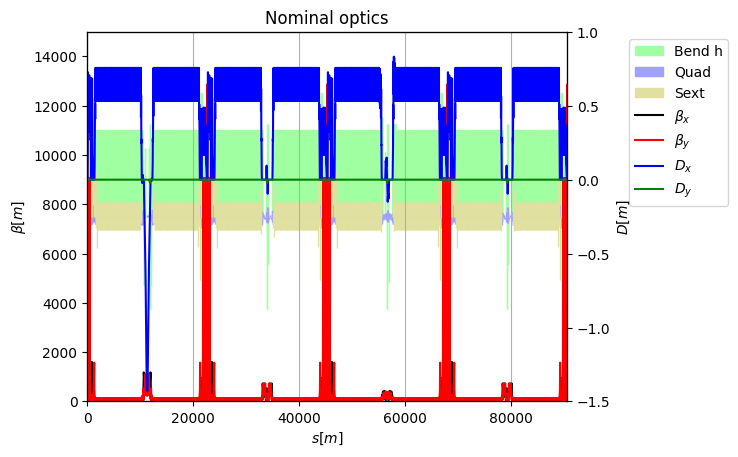

In [7]:
p = tw_nominal.plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Nominal optics');

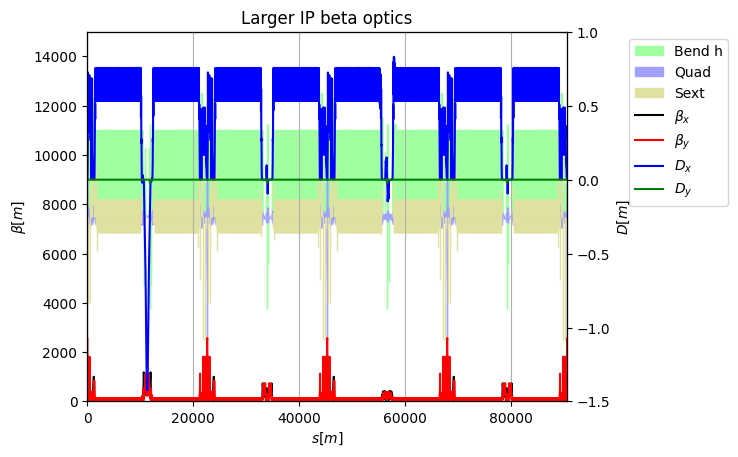

In [8]:
p = tw_larger_ip_beta.plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Larger IP beta optics');

### One experimental straight and neighbouring arcs

Compare the optics around `ipd`, including the dispersion suppressors and 500 m of arc on each side. Keep the same vertical scales as above.

In [9]:
s_start = tw_nominal['s', 'end_arc_start_ds_ipd'] - 500
s_end = tw_nominal['s', 'end_ds_start_arc_ipd'] + 500

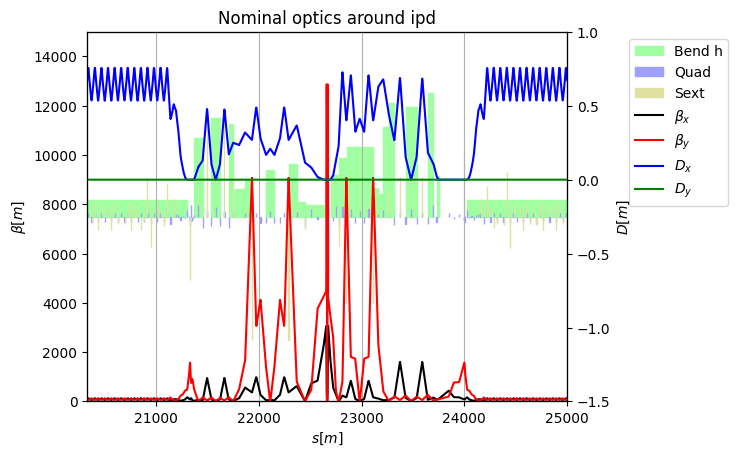

In [10]:
p = tw_nominal.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Nominal optics around ipd');

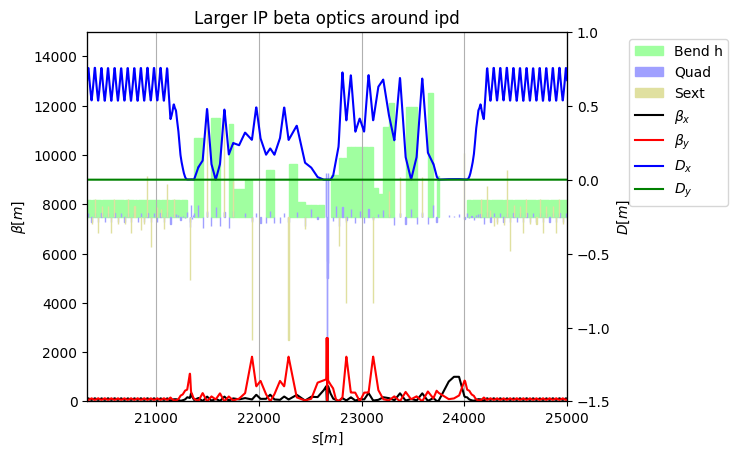

In [11]:
p = tw_larger_ip_beta.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Larger IP beta optics around ipd');

### Final doublets and neighbouring quadrupoles

Zoom into the region within 100 m of `ipd` on each side. Compare the beta functions for both optics using the same vertical scales.

In [12]:
s_start = tw_nominal['s', 'ipd'] - 100
s_end = tw_nominal['s', 'ipd'] + 100

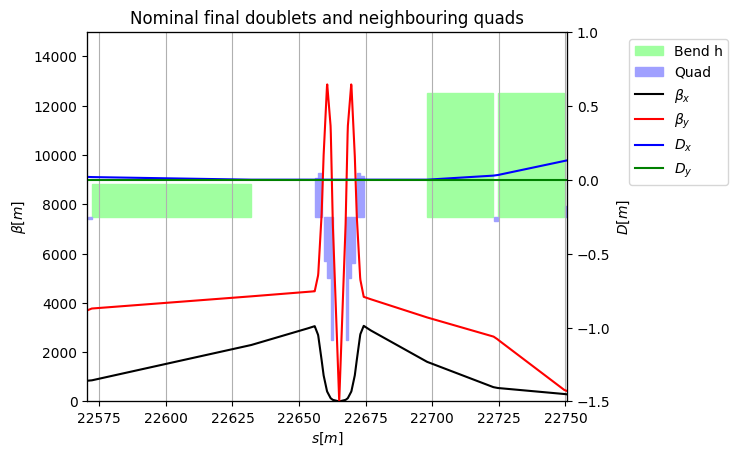

In [13]:
p = tw_nominal.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Nominal final doublets and neighbouring quads');

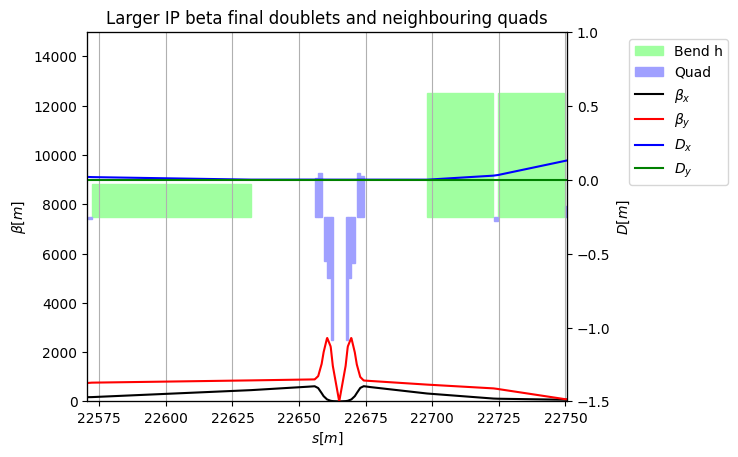

In [14]:
p = tw_larger_ip_beta.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Larger IP beta final doublets and neighbouring quads');

### Natural chromaticities

Now switch off the sextupoles and repeat the Twiss calculation for both optics to obtain their natural chromaticities. Use `delta_chrom=1e-6` because larger momentum offsets can make the optics unstable without sextupoles.

In [15]:
table = line.get_table()
sextupoles = table.rows.match(element_type='Sextupole')

### Nominal optics without sextupoles

In [16]:
env.vars.load('optics_nominal.json')
line.set(sextupoles, k2=0)
tw_nominal_natural = line.twiss4d(delta_chrom=1e-6)

### Larger IP beta optics without sextupoles

In [17]:
env.vars.load('optics_larger_ip_beta.json')
line.set(sextupoles, k2=0)
tw_larger_ip_beta_natural = line.twiss4d(delta_chrom=1e-6)

### Compare the natural chromaticities

Report `dqx` and `dqy` for each optics.

In [18]:
print(f"NOMINAL: {tw_nominal_natural.dqx:.2f}, {tw_nominal_natural.dqy:.2f}")
print(f"LARGER IP BETA: {tw_larger_ip_beta_natural.dqx:.2f}, {tw_larger_ip_beta_natural.dqy:.2f}")

NOMINAL: -512.54, -3145.90
LARGER IP BETA: -245.64, -778.03


Why does increasing the IP beta reduce the magnitude of the natural chromaticity?